<a href="https://colab.research.google.com/github/aviksarkar0204-stack/AI_LAB_ASSIGNMENTS/blob/main/Assignment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score
#Training data
#[Study, Hours,Attendence]
X=np.array([
    [1,50],
    [2,55],
    [3,60],
    [5,75],
    [6,80],
    [7,85]
])

#Target
#0=Fail, 1=Pass
y=np.array([0,0,0,1,1,1])

#Create Perception model
model=Perceptron(max_iter=1000, random_state=42)

#Train the model
model.fit (X,y)

#Predictions
y_pred=model.predict(X)

#Display results
print("Actual Values: ",y)
print("Predicted Values: ",y_pred)

#Accuracy
accuracy=accuracy_score(y,y_pred)
print("Accuracy: ",accuracy*100,"%")

#Model Parameters
print ("\nWeights: ",model.coef_)
print("Bias: ",model.intercept_)


#Predict a new student
new_student =np.array([[4,70]])
prediction =model.predict(new_student)
if prediction[0]==1:
    print("\nNew student Predictionn:PASS")
else:
    print("\nNew Student Prediction :FAIL")

Actual Values:  [0 0 0 1 1 1]
Predicted Values:  [0 0 0 0 0 0]
Accuracy:  50.0 %

Weights:  [[ 38. -15.]]
Bias:  [-6.]

New Student Prediction :FAIL


Actual Values :  [0 0 0 1 1 1]
Predicted Values:  [0 0 0 1 1 1]

New Student Prediction : PASS


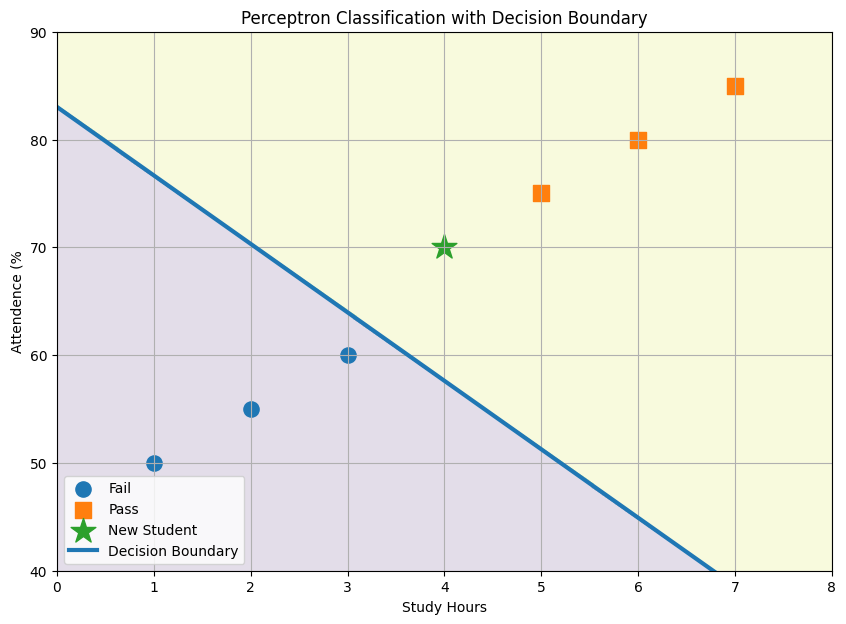

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Datasets
# --------------------------------------------------
# [Study,Hours,Attendence]
X = np.array([
    [1,50],
    [2,55],
    [3,60],
    [5,75],
    [6,80],
    [7,85]
])

# 0=Fail,1=Pass
y = np.array([0,0,0,1,1,1])


# ----------------------------------------------------------
# Perceptron with Scaling
# -----------------------------------------------------------
model = make_pipeline(
    StandardScaler(),
    Perceptron(max_iter=1000, random_state=42)
)

model.fit(X,y)

predictions = model.predict(X)

print("Actual Values : ",y)
print("Predicted Values: ",predictions)


# New Student
new_student = np.array([[4,70]])

prediction =model.predict(new_student)

if prediction[0]==1:
    print("\nNew Student Prediction : PASS")
else:
    print("\nNew Strudent Prediction : FAIL")

X_min,X_max = 0,8
y_min,y_max = 40,90

xx,yy = np.meshgrid(
    np.linspace(X_min,X_max,200),
    np.linspace(y_min,y_max,200)
)

grid = np.c_[xx.ravel(),yy.ravel()]

Z =model.predict(grid)

Z = Z.reshape(xx.shape)


plt.figure(figsize =(10,7))

# Decision regions
plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.15

)

# Fail Points
plt.scatter(
    X[y == 0,0],
    X[y == 0,1],
    marker = 'o',
    s=120,
    label = 'Fail'
)

# Pass Points
plt.scatter(
    X[y == 1,0],
    X[y == 1,1],
    marker = 's',
    s=120,
    label = 'Pass'
)

plt.scatter (
    new_student[0,0],
    new_student[0,1],
    marker = '*',
    s = 350,
    label = "New Student"
)

# get transformed -space coeficients
Scaler = model.named_steps['standardscaler']
perceptron = model.named_steps['perceptron']

w = perceptron.coef_[0]
b = perceptron.intercept_[0]

# Convert bpundary back to original feature space
mean = Scaler.mean_
scale = Scaler.scale_

w_original = w/scale

b_original = b- np.sum(w*mean/scale)

x_values = np.linspace(0,8,100)

y_values = -(
    w_original[0] * x_values + b_original
)/w_original[1]

plt.plot(
    x_values,
    y_values,
    linewidth = 3,
    label = "Decision Boundary"
)

plt.xlabel("Study Hours")
plt.ylabel("Attendence (%")

plt.title("Perceptron Classification with Decision Boundary")
plt.legend()
plt.grid(True)

plt.xlim(0,8)
plt.ylim(40,90)

plt.show()

K= 3
Pass

 Nearest neighbors: 
Student 2 Distance 5.1 Class=  PASS
Student 5 Distance 10.05 Class=  FAIL
Student 4 Distance 10.2 Class=  PASS


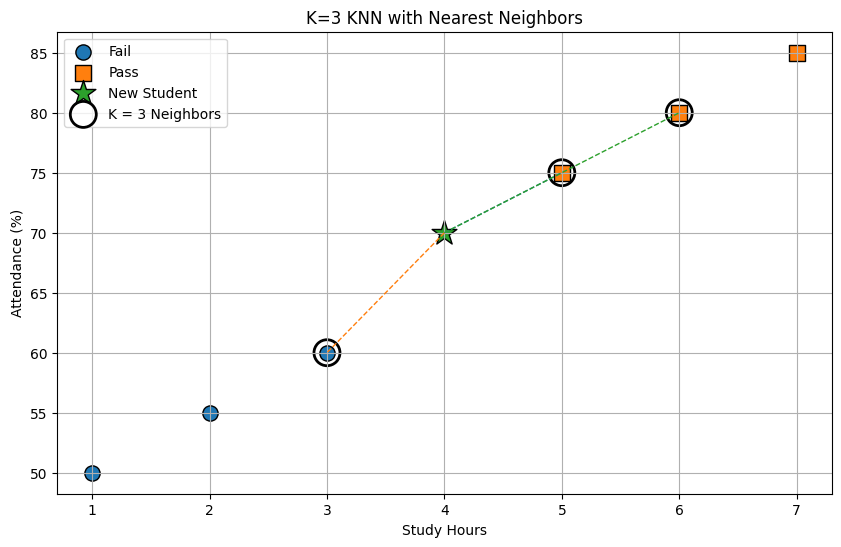

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

X= np.array([
[2,55],
[5,75],
[1,50],
[6,80],
[3,60],
[7,85]])

y= np.array([0, 1, 0, 1, 0, 1])

k=3
knn= KNeighborsClassifier(n_neighbors=k)
knn.fit(X,y)

new_student =  np.array([[4,70]])
prediction= knn.predict(new_student)
print("K=",k)
if prediction[0] == 1:
    print("Pass")
else:
    print("Fail")

distances, indices = knn.kneighbors(new_student)

print("\n Nearest neighbors: ")

for i in range(k):
    index = indices[0][i]
    print(
        "Student", index +1,
        "Distance", round(distances[0][i],2),
        "Class= ",
        "PASS" if y[index] == 1 else 'FAIL'
        )
plt.figure(figsize=(10,6))
plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    marker="o",
    s=120,
    label="Fail",
    edgecolors="black"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    marker="s",
    s=120,
    label="Pass",
    edgecolors="black"
)

plt.scatter(
    new_student[:, 0],
    new_student[:, 1],
    marker="*",
    s=350,
    label="New Student",
    edgecolors="black"
)

nearest = X[indices[0]]
plt.scatter(
    nearest[:, 0],
    nearest[:,1],
    facecolors='none',
    edgecolors= 'black',
    s=350,
    linewidths=2,
    label= 'K = 3 Neighbors'
)

for point in nearest:
    plt.plot(
        [new_student[0,0], point[0]],
        [new_student[0,1], point[1]],
        linestyle= '--',
        linewidth=1
    )

plt.xlabel('Study Hours')
plt.ylabel('Attendance (%)')
plt.title('K=3 KNN with Nearest Neighbors')
plt.legend()
plt.grid(True)
plt.show()